# PartB - Supplement: glacier model differences versus global warming (all climate scenarios)

Three full-width figures with the same layout and the same region order (Global + 19 regions, sorted by the 2020 glacier mass as in Figs. 4-6), one dot per glacier model and climate scenario:
1. steady-state mass: difference to the multi-model median (% of 2020 glacier mass)
2. mass after 80 years: difference to the multi-model median (% of 2020 glacier mass), same y axis as 1.
3. response timescale (80 %, years from the simulation start): **absolute** values, three variants of the y axis

Replaces the 5x4 scatterplots in `PartB_Fig2_3_glacier_model_differences.ipynb` (cells 31 and 80): same idea, but with the differences recomputed as in Fig. 4 (median of the relative values of all glacier models in a region, not the stored `delta ... to median model` columns), a fixed y range (-60 to 80 %) instead of the old shared range that was set by the coldest climate scenarios (values outside: triangles at the axis limit), printed size 17 x 21 cm with 7 pt text, and the region order / names / colours of the other manuscript figures.

## Settings

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42           # keep the text editable in the pdf

fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
fn_after80yrs = 'PartB_data/after80yrs_relative_volume_change.csv'
fn_resp_time = 'PartB_data/resp_time_non_shifted_for_deltaT_rgi_reg_roll_volume_area_21yravg.csv'   # as Fig. 5 (counted from the simulation start)
resp_time_perc = 80              # response timescale: years until 80 % of the total mass change (as Fig. 5)
ref_period = '1995-2014_hist'

# printed size: two-column (full-width) figure, include with width=\linewidth, so fs is the printed font size
fig_width_cm, fig_height_cm = 17.0, 21.0
fs = 7
temp_bin_main = (2.0, 4.0)       # warming bin of the main figures, shaded in every panel

fig_dir = 'figures_partB/supplement_vs_warming/'
os.makedirs(fig_dir, exist_ok=True)

# y axes (CL 22.10.): the same fixed range in all panels instead of a free range per region
ylim_mass = (-60, 80)            # % of 2020 glacier mass, the same for steady state and after 80 years (no value of the 2.0-4.0 degC bin is outside)
yticks_mass = np.arange(-60, 81, 20)
# response timescale on a linear axis: two fixed ranges, slowly responding regions (and Global) 0-1200 years, the others 0-400 years
rt_slow = ['All', '19', '03', '05', '09', '04', '07', '06']
ylim_rt = {r: (0, 1200) if r in rt_slow else (0, 400) for r in ['All'] + [f'{i:02d}' for i in range(1, 20)]}

In [2]:
reg_names = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}
# Global first, then sorted by the 2020 glacier mass (descending) as in Figs. 4-6
reg_order = ['All', '19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']

global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv files, all others are the same
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}

## 1. Data

Differences per climate scenario (no median over scenarios). Checks: two numbers of Fig. 4 / the text (2.0 to 4.0 °C).

In [3]:
rc = 'relative volume change (in %)'

def diff_to_multi_model_median(fn):
    """difference of every glacier model to the multi-model median of all glacier models in the region (Global: the four
    global models), per climate scenario, in % of the 2020 glacier mass (as 'a' in the portrait notebook, Fig. 4)"""
    pd_m = pd.read_csv(fn, index_col=0)
    pd_m['model'] = pd_m.model_author.replace(model_names_csv)
    pd_m['reg'] = pd_m.rgi_reg.replace({'Global': 'All'})
    ref = pd_m.groupby(['reg', 'gcm', 'period_scenario'])[rc].transform('median')
    pd_m['value'] = pd_m[rc] - ref
    return pd_m[['reg', 'model', 'gcm', 'period_scenario', 'temp_ch_ipcc', rc, 'value']]

pd_ss = diff_to_multi_model_median(fn_steady_state)
pd_80 = diff_to_multi_model_median(fn_after80yrs)

# response timescale (absolute, years from the simulation start), only volume and without OGGM-VAS (as Fig. 5)
pd_rt = pd.read_csv(fn_resp_time, index_col=0)
pd_rt = pd_rt.loc[(pd_rt.metric == 'volume_m3') & (pd_rt.model_author != 'OGGM-VAS')].copy()
pd_rt['model'] = pd_rt.model_author.replace(model_names_csv)
pd_rt['reg'] = pd_rt.rgi_reg.str.replace('RGI', '')
pd_rt['value'] = pd_rt[f'resp_time_-{resp_time_perc}%']
# number of climate scenarios with an estimate per region and glacier model (only experiments with >= 25 % mass change)
n_scen = pd_ss.groupby(['gcm', 'period_scenario']).ngroups
n_rt = pd_rt.groupby(['reg', 'model']).size().unstack('model')

# checks: same numbers as in the portrait figure / text (2.0 to 4.0 degC, medians over the climate scenarios)
_b = pd_ss.loc[(pd_ss.temp_ch_ipcc >= 2.0) & (pd_ss.temp_ch_ipcc <= 4.0)].groupby(['reg', 'model']).value.median()
np.testing.assert_allclose(_b.loc[('All', 'GloGEMflow')], 18.3, atol=0.1)
np.testing.assert_allclose(_b.loc[('14', 'OGGM')], -16.5, atol=0.1)
print(f'{n_scen} climate scenarios; response timescale estimates per region and glacier model (of {n_scen}):')
print(n_rt.reindex(reg_order)[global_models + regional_models].fillna(0).astype(int).to_string())

80 climate scenarios; response timescale estimates per region and glacier model (of 80):
model  PyGEM-OGGM  GloGEMflow  OGGM  GLIMB  GloGEMflow3D  Kraaijenbrink  GO  CISM2
reg                                                                               
All            76          53    66     68             0              0   0      0
19             77          19    60     74             0              0   0      0
03             80          33    55     68             0              0   0      0
01             71          68    66     63             0              0   0      0
05             78          63    71     70             0              0   0      0
09             75          70    72     67             0              0   0      0
04             80          77    80     80             0              0   0      0
07             70          59    67     69             0              0   0      0
17             68          75    72     56             0              0   0      

## 2. Plotting function

In [4]:
def grid_vs_warming(pd_v, ylabel, kind='difference', logy=False, ylim_shared=None, ylim_by_reg=None):
    """5 x 4 panels (Global + 19 regions): one dot per glacier model and climate scenario, x = global warming.
    kind='difference': zero line; kind='absolute': no zero line.
    ylim_shared=(lo, hi): the same y axis in all panels; values outside are drawn as triangles at the axis limit.
    ylim_by_reg={reg: (lo, hi)}: a few fixed y ranges, given per region (values outside again as triangles).
    both None: independent y axes (full range in every panel)."""
    shared = ylim_shared is not None
    fixed = shared or ylim_by_reg is not None
    fig, axs = plt.subplots(5, 4, figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54), sharex=True, sharey=shared)
    fig.subplots_adjust(left=0.075, right=0.99, bottom=0.05, top=0.935, wspace=0.08 if shared else 0.25, hspace=0.24)
    t_min, t_max = -0.3, 7.1
    n_out = 0
    for ax, reg in zip(axs.flatten(), reg_order):
        _p = pd_v.loc[pd_v.reg == reg]
        ylim = ylim_shared if shared else (ylim_by_reg[reg] if ylim_by_reg is not None else None)
        ax.axvspan(*temp_bin_main, color='0.93', lw=0, zorder=0)
        if kind == 'difference':
            ax.axhline(0, color='0.3', lw=0.6, zorder=1)
        for m in global_models + regional_models:      # regional models on top (fewer points)
            _pm = _p.loc[_p.model == m]
            if len(_pm) == 0:
                continue
            is_glob = m in global_models
            style = dict(mfc=dict_model_col[m], mec='0.25', mew=0.25, alpha=0.9, ls='none', zorder=3 if is_glob else 4)
            x, v = _pm.temp_ch_ipcc.values, _pm.value.values
            if fixed:
                lo, hi = ylim
                inside = (v >= lo) & (v <= hi)
                # values outside the axis range: triangles at the limit
                for sel, y_edge, mk in [(v > hi, hi, '^'), (v < lo, lo, 'v')]:
                    if sel.any():
                        ax.plot(x[sel], np.full(sel.sum(), y_edge), mk, ms=2.8, clip_on=False, **style)
                        n_out += sel.sum()
                x, v = x[inside], v[inside]
            ax.plot(x, v, 'o' if is_glob else 'D', ms=2.4 if is_glob else 2.1, **style)
        ax.set_xlim(t_min, t_max)
        ax.set_xticks([0, 2, 4, 6])
        if logy:
            ax.set_yscale('log')
        if fixed:
            ax.set_ylim(*ylim)
        ax.tick_params(labelsize=fs, length=2, pad=1.5, width=0.5)
        ax.tick_params(which='minor', length=1, width=0.4)
        for sp in ax.spines.values():
            sp.set_linewidth(0.5)
        # region name above the panel (inside, it would hide dots); centred, so that the longest name may extend into the gaps
        ax.set_title(reg_names[reg], fontsize=fs, pad=5, fontweight='bold' if reg == 'All' else 'normal')
    for ax in axs[-1]:
        ax.set_xlabel('global warming (\u00b0C)', fontsize=fs, labelpad=1)
    fig.supylabel(ylabel, fontsize=fs, x=0.005)
    # legend: the glacier models (circles: global, diamonds: regional) and, if any, the triangles for values outside the axis range
    # two rows: global models in the first, regional models in the second (the legend is filled column by column)
    h = {m: Line2D([], [], marker='o' if m in global_models else 'D', ls='none', ms=3.2 if m in global_models else 2.9,
                   mfc=dict_model_col[m], mec='0.25', mew=0.3, label=m) for m in global_models + regional_models}
    handles = [x for g, r in zip(global_models, regional_models) for x in (h[g], h[r])]
    if n_out > 0:
        handles.append(Line2D([], [], marker='^', ls='none', ms=3.2, mfc='0.7', mec='0.25', mew=0.3, label='outside the axis range'))
    fig.legend(handles=handles, loc='upper center', ncol=(len(handles) + 1) // 2, fontsize=fs, frameon=False, handletextpad=0.1,
               columnspacing=1.2, bbox_to_anchor=(0.53, 1.005))
    print(f'values outside the shared axis range: {n_out} of {len(pd_v)} ({100 * n_out / len(pd_v):.1f} %)')
    return fig, axs

In [5]:
import itertools, matplotlib.text as mtext
def check_text(fig):
    """smallest font, text outside the figure and overlapping text (only tick labels that are drawn, i.e. inside the axis limits)"""
    fig.canvas.draw(); r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches() * 2.54
    hidden = set()
    for ax in fig.axes:
        for axis, lim in [(ax.xaxis, ax.get_xlim()), (ax.yaxis, ax.get_ylim())]:
            lo, hi = min(lim), max(lim)
            for tick in axis.get_major_ticks() + axis.get_minor_ticks():
                if not (lo - 1e-9 <= tick.get_loc() <= hi + 1e-9):
                    hidden.add(id(tick.label1)); hidden.add(id(tick.label2))
    bbs = []
    for t in fig.findobj(mtext.Text):
        if id(t) in hidden or not t.get_visible() or not t.get_text().strip(): continue
        bb = t.get_window_extent(r); dpi = fig.dpi
        bbs.append((t.get_text().replace('\n', '|')[:30], bb.x0/dpi*2.54, bb.y0/dpi*2.54, bb.x1/dpi*2.54, bb.y1/dpi*2.54, t.get_fontsize()))
    out = [(b[0], round(b[1], 2), round(b[3], 2)) for b in bbs if b[1] < 0.02 or b[2] < 0.02 or b[3] > W - 0.02 or b[4] > H - 0.02]
    ov = [(a[0], b[0]) for a, b in itertools.combinations(bbs, 2) if a[1] < b[3] and b[1] < a[3] and a[2] < b[4] and b[2] < a[4]]
    print('figure %.1f x %.1f cm | font sizes %s | text at/outside edge: %s | overlapping text: %s' % (W, H, sorted(set(round(b[5], 1) for b in bbs)), out, ov))

## 3. Figures

### Steady-state mass

values outside the shared axis range: 102 of 7680 (1.3 %)
figure 17.0 x 21.0 cm | font sizes [7.0] | text at/outside edge: [] | overlapping text: []


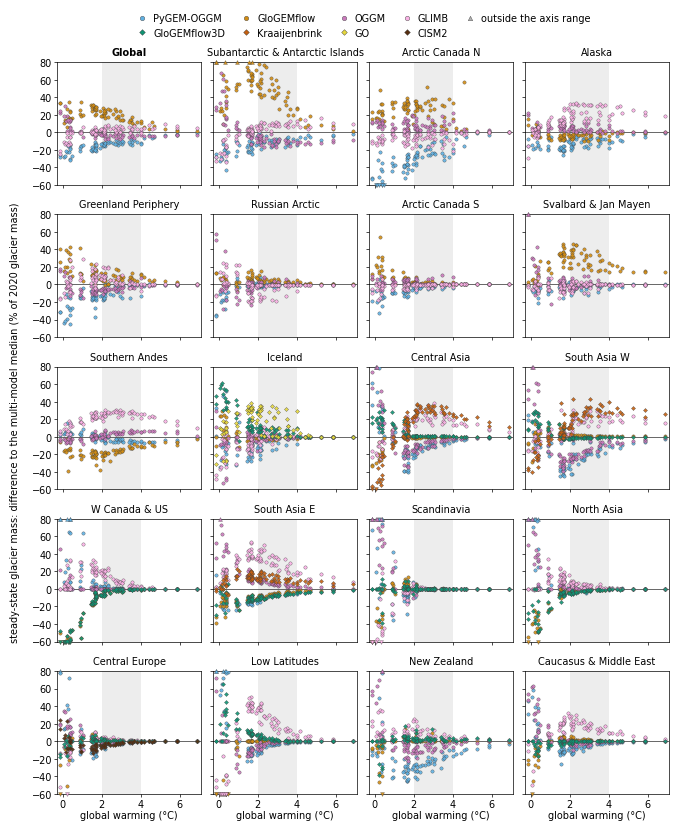

In [6]:
fig, axs = grid_vs_warming(pd_ss, 'steady-state glacier mass: difference to the multi-model median (% of 2020 glacier mass)',
                           ylim_shared=ylim_mass)
axs[0, 0].set_yticks(yticks_mass)      # shared y axis
check_text(fig)
fn_out = fig_dir + 'suppl_steady_state_diff_to_multi_model_median_vs_warming'
fig.savefig(fn_out + '.png', dpi=300)
fig.savefig(fn_out + '.pdf')
plt.show()

### Mass after 80 years

values outside the shared axis range: 12 of 7680 (0.2 %)
figure 17.0 x 21.0 cm | font sizes [7.0] | text at/outside edge: [] | overlapping text: []


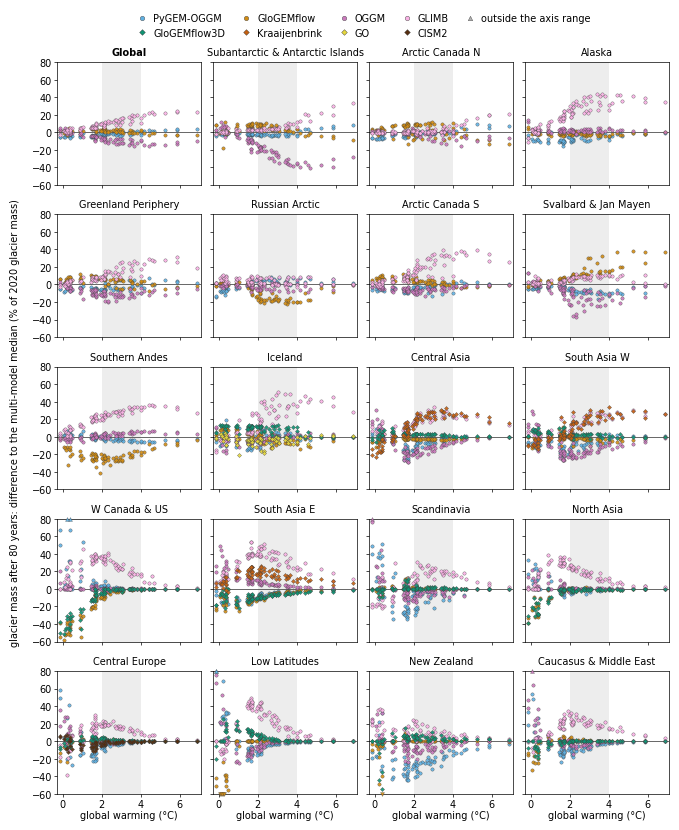

In [7]:
fig, axs = grid_vs_warming(pd_80, 'glacier mass after 80 years: difference to the multi-model median (% of 2020 glacier mass)',
                           ylim_shared=ylim_mass)
axs[0, 0].set_yticks(yticks_mass)      # shared y axis
check_text(fig)
fn_out = fig_dir + 'suppl_after80yrs_diff_to_multi_model_median_vs_warming'
fig.savefig(fn_out + '.png', dpi=300)
fig.savefig(fn_out + '.pdf')
plt.show()

### Response timescale

**Absolute** response timescales instead of differences to the multi-model median: a response timescale is only estimated if the mass changes by at least 25 %, so some glacier models have no estimate in some climate scenarios (GloGEMflow: 19 and 33 of 80 in Subantarctic & Antarctic Islands and Arctic Canada N, see the table in section 1). A difference to the multi-model median would then be computed over fewer glacier models and would jump between climate scenarios (see the comparison below).

Three variants of the y axis: `linear_two_ranges` (0-1200 years for Global and the slowly responding regions, 0-400 years for the others; suggested), `linear_shared` (0-1200 years everywhere, as Science Fig. S11; the fast regions are hardly readable) and `log_shared` (8-3000 years, logarithmic).

values at the lower limit of 10 years: 50 of 6251 {'16': 47, '11': 2, '12': 1}
linear_two_ranges
values outside the shared axis range: 49 of 6251 (0.8 %)
figure 17.0 x 21.0 cm | font sizes [7.0] | text at/outside edge: [] | overlapping text: []


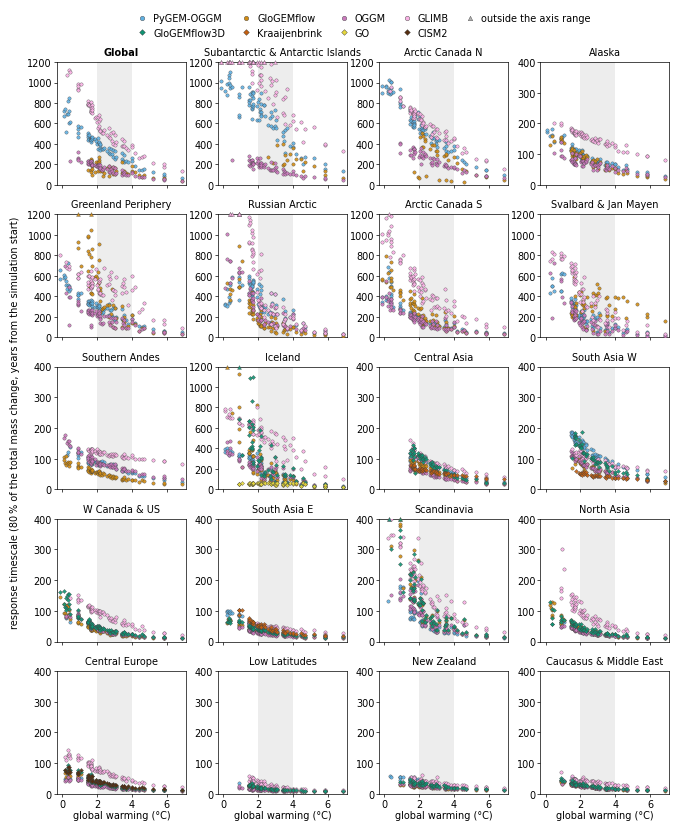

linear_shared
values outside the shared axis range: 45 of 6251 (0.7 %)
figure 17.0 x 21.0 cm | font sizes [7.0] | text at/outside edge: [] | overlapping text: []


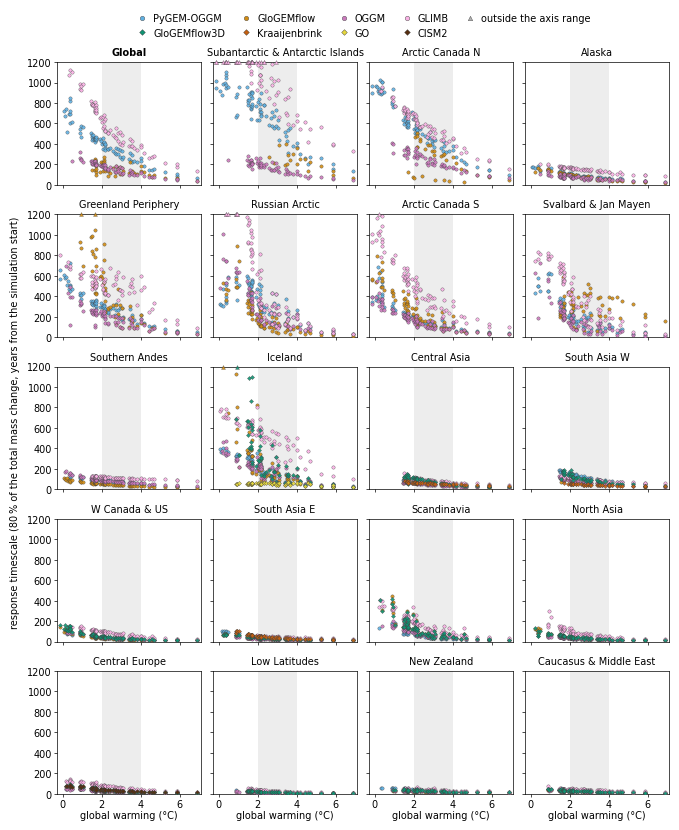

log_shared
values outside the shared axis range: 0 of 6251 (0.0 %)
figure 17.0 x 21.0 cm | font sizes [7.0] | text at/outside edge: [] | overlapping text: []


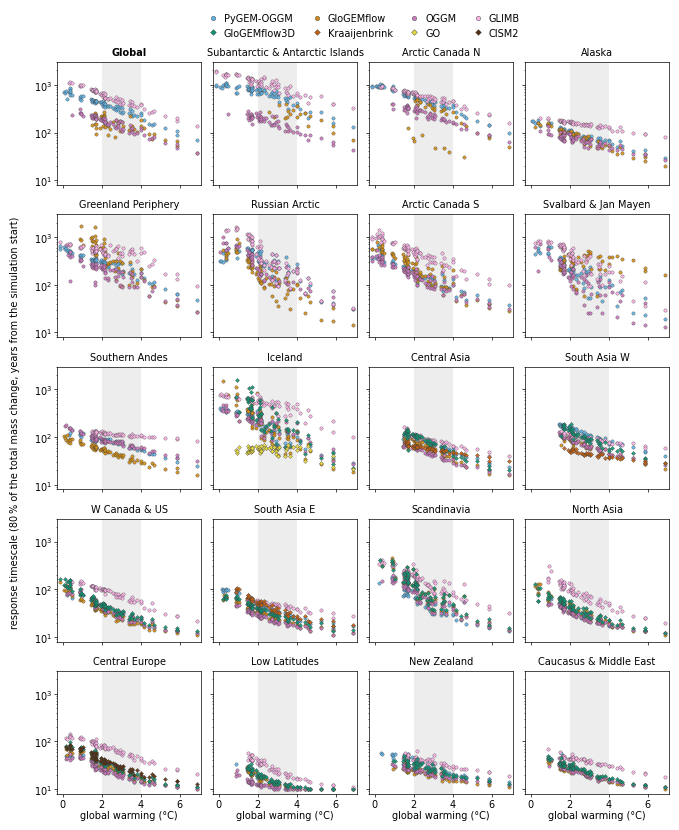

In [8]:
# three variants of the y axis, to decide which one goes into the supplement (10 years is the lower limit of the method: 21-year centred rolling mean)
print('values at the lower limit of 10 years:', int((pd_rt.value <= 10).sum()), 'of', len(pd_rt), pd_rt.loc[pd_rt.value <= 10].reg.value_counts().to_dict())
ylabel_rt = f'response timescale ({resp_time_perc}\u202f% of the total mass change, years from the simulation start)'
variants = {'linear_two_ranges': dict(ylim_by_reg=ylim_rt),           # suggested
            'linear_shared': dict(ylim_shared=(0, 1200)),             # as Science Fig. S11: the fast regions are hardly readable
            'log_shared': dict(logy=True, ylim_shared=(8, 3000))}
for name, kw in variants.items():
    print(name)
    fig, axs = grid_vs_warming(pd_rt, ylabel_rt, kind='absolute', **kw)
    check_text(fig)
    fn_out = fig_dir + f'suppl_response_timescale_{resp_time_perc}_vs_warming_{name}'
    fig.savefig(fn_out + '.png', dpi=300)
    fig.savefig(fn_out + '.pdf')
    plt.show()

#### For comparison only (not for the manuscript): differences to the multi-model median

values outside the shared axis range: 0 of 6251 (0.0 %)


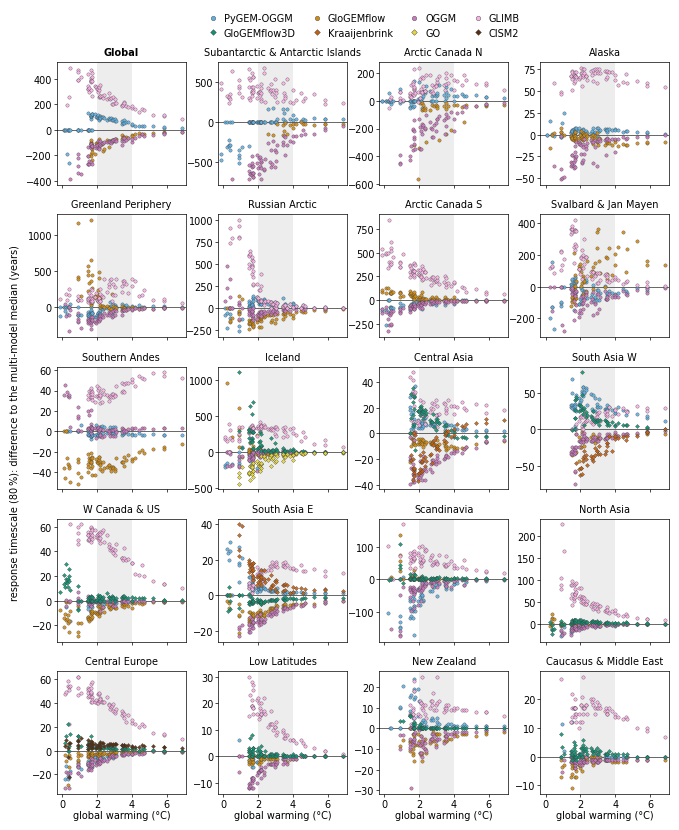

In [9]:
# NOT for the manuscript, only to compare: difference to the multi-model median of the glacier models WITH an estimate in a scenario.
# Where a glacier model has no estimate (e.g. GloGEMflow in Subantarctic & Antarctic Islands and Arctic Canada N, but also Global),
# the multi-model median is taken over three glacier models, so that one of them is exactly 0 and the median jumps between scenarios.
pd_rt_d = pd_rt.copy()
pd_rt_d['value'] = pd_rt_d.value - pd_rt_d.groupby(['reg', 'gcm_period_scenario']).value.transform('median')
fig, axs = grid_vs_warming(pd_rt_d, f'response timescale ({resp_time_perc}\u202f%): difference to the multi-model median (years)')
plt.show()

## Caption drafts (LaTeX)

```latex
\begin{figure*}[ht]
\centering
\includegraphics[width=\linewidth]{fig/suppl_steady_state_diff_to_multi_model_median_vs_warming.png}
\caption{Differences of each glacier model to the multi-model median in steady-state glacier mass versus global warming, for all 80 climate scenarios, globally and for the 19 RGI regions (sorted by their 2020 glacier mass). Each dot shows one glacier model (circles: global glacier models, diamonds: regional glacier models) and one climate scenario; the multi-model median is taken over all glacier models available in a region (Global: the four global glacier models). Differences are given in \% of the 2020 glacier mass. Triangles mark values outside the y-axis range (1.3\,\% of all values, none for 2.0 to 4.0\,$^\circ$C), drawn at the axis limit. The grey band marks the 2.0 to 4.0\,$^\circ$C warming bin of Figs.~\ref{fig:app_gmip3_model_differences_magnitude} and \ref{fig:app_gmip3_steady_state_model_differences}.}
\label{fig:suppl_ss_diff_vs_warming}
\end{figure*}

\begin{figure*}[ht]
\centering
\includegraphics[width=\linewidth]{fig/suppl_after80yrs_diff_to_multi_model_median_vs_warming.png}
\caption{As Fig.~\ref{fig:suppl_ss_diff_vs_warming}, but for the glacier mass after 80 years (mean over the simulation years 70 to 89 after 2020; TODO check Methods). 0.2\,\% of all values are outside the y-axis range.}
\label{fig:suppl_80yrs_diff_vs_warming}
\end{figure*}

% for the variant 'linear_two_ranges'
\begin{figure*}[ht]
\centering
\includegraphics[width=\linewidth]{fig/suppl_response_timescale_80_vs_warming_linear_two_ranges.png}
\caption{Response timescale (years from the simulation start until 80\,\% of the total mass change has occurred) of each glacier model versus global warming, globally and for the 19 RGI regions. Each dot shows one glacier model and one climate scenario; response timescales are only estimated if the glacier mass changes by at least 25\,\% (Sect.~TODO). Note the two y-axis ranges (0 to 1200 and 0 to 400 years); triangles mark values outside them (0.8\,\% of all values). 10 years is the lower limit of the method (21-year centred rolling mean). GloGEMflow provides a response timescale for only 19 and 33 of the 80 climate scenarios in the Subantarctic $\&$ Antarctic Islands and Arctic Canada North, which is why these regions are not shown in Fig.~\ref{TODO_fig5}. The grey band marks the 2.0 to 4.0\,$^\circ$C warming bin.}
\label{fig:suppl_resp_time_vs_warming}
\end{figure*}
```